# 2027 AFC Asian Cup: Monte Carlo simulation (10,000 runs)
**Step 2 of the project.** Omar Elouny · CSCI-630.01

Uses the `afc_sim` package built on the model-testing notebook: XGBoost match engine → Poisson score layer → official 24-team format (group tiebreakers, best four thirds, bracket) → extra time and penalties. Run from the repository root with the Kaggle CSVs in `data/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd
from IPython.display import Image, display
from afc_sim import MatchEngine, ShootoutModel, Simulator, build_features, load_raw, train_xgb
pd.set_option("display.width", 200)

## 1. Build the engine (data → Elo/features → XGBoost → W/D/L table for all 24 teams)

In [2]:
res, sho = load_raw("data")
df, state = build_features(res)
model = train_xgb(df, train_through_year=2026)           # tuned hyper-parameters, refit on all data
engine = MatchEngine(model, state)
shoot = ShootoutModel.fit(df, sho)
print(f"{len(res):,} matches through {res.date.max().date()}")
print(json.dumps(shoot.diagnostics, indent=1))

49,945 matches through 2026-10-06
{
 "n_shootouts": 699,
 "coef_elo_per100": 0.1357600996210086,
 "coef_record": 0.1338706097439306,
 "holdout_from": 2015,
 "n_holdout": 229,
 "holdout_logloss": 0.68507186020923,
 "coin_logloss": 0.6931471805599453,
 "first_shooter_win_rate": 0.5241635687732342,
 "n_first_shooter": 269
}


## 2. Run 10,000 tournaments

In [3]:
sim = Simulator(engine, shoot)
out = sim.run(10_000, seed=2027)
tab = out.table
display((tab[["Group","Elo","Win group","Advance","QF","SF","Final","Champion"]]*[1,1,100,100,100,100,100,100]).round(1))

,Group,Elo,Win group,Advance,QF,SF,Final,Champion
Japan,F,1975,86.8,99.4,80.4,65.4,46.4,32.4
Australia,D,1898,76.5,99.3,78.0,57.4,30.1,17.2
Saudi Arabia,A,1739,73.6,97.8,79.4,53.9,29.7,14.5
Iran,C,1865,75.7,98.2,77.1,45.2,26.0,12.8
South Korea,E,1845,68.4,98.5,62.7,39.7,24.0,11.3
Uzbekistan,B,1750,48.9,92.8,63.6,24.7,11.2,3.8
Jordan,B,1714,39.0,90.4,57.2,20.7,7.7,2.8
United Arab Emirates,E,1680,23.6,90.6,31.3,14.9,5.4,1.5
Iraq,D,1664,20.3,91.0,37.9,16.2,5.3,1.3
Palestine,A,1624,13.2,74.2,36.8,11.1,2.7,0.5


Reproducibility check against the saved `results/team_probabilities.csv` (same seed → same numbers):

In [4]:
saved = pd.read_csv("results/team_probabilities.csv", index_col=0)
print("max abs difference vs saved results:", float((tab[saved.columns[1:]] - saved[saved.columns[1:]]).abs().max().max()))
print(json.dumps({k: v for k, v in out.diagnostics.items() if k in ("tiebreak_per_sim","knockout_decided_in","max_fit_error")}, indent=1))

max abs difference vs saved results: 0.0
{
 "tiebreak_per_sim": 2.9526,
 "knockout_decided_in": {
  "90": 0.7563333333333333,
  "PEN": 0.14432666666666666,
  "ET": 0.09934
 },
 "max_fit_error": 1.4127239341549247e-07
}


## 3. Figures\nGenerated by `make_report.py` (full narrative in `REPORT.md`).

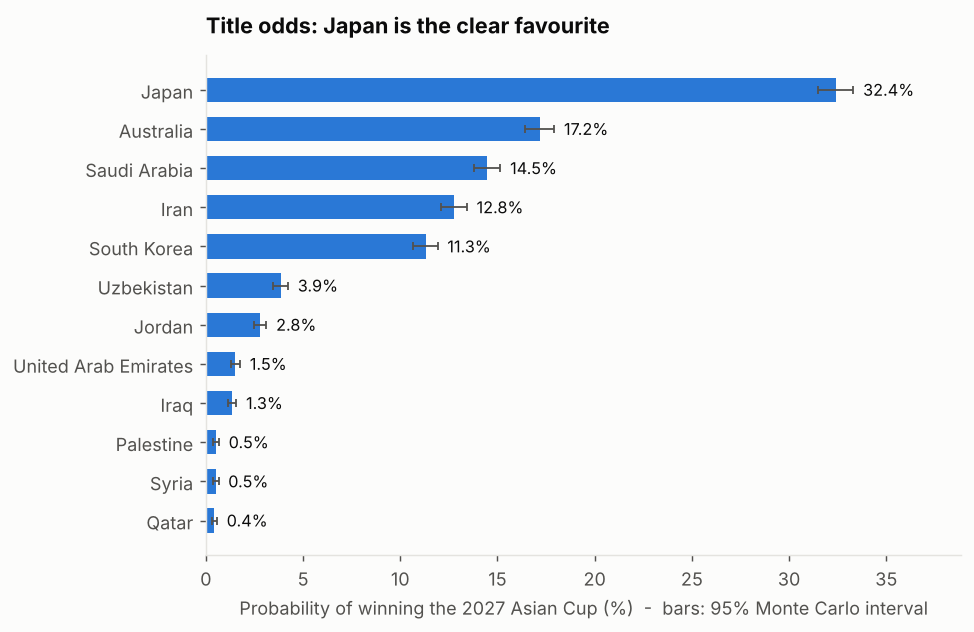

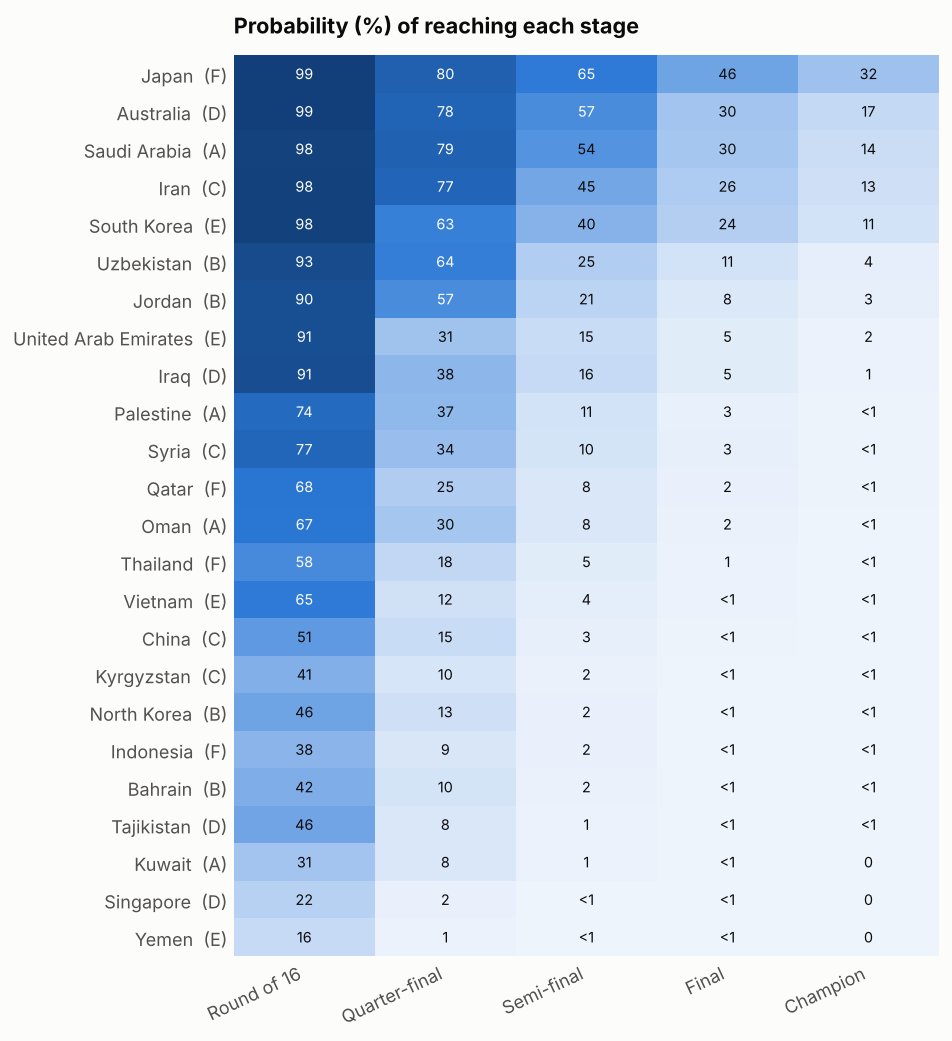

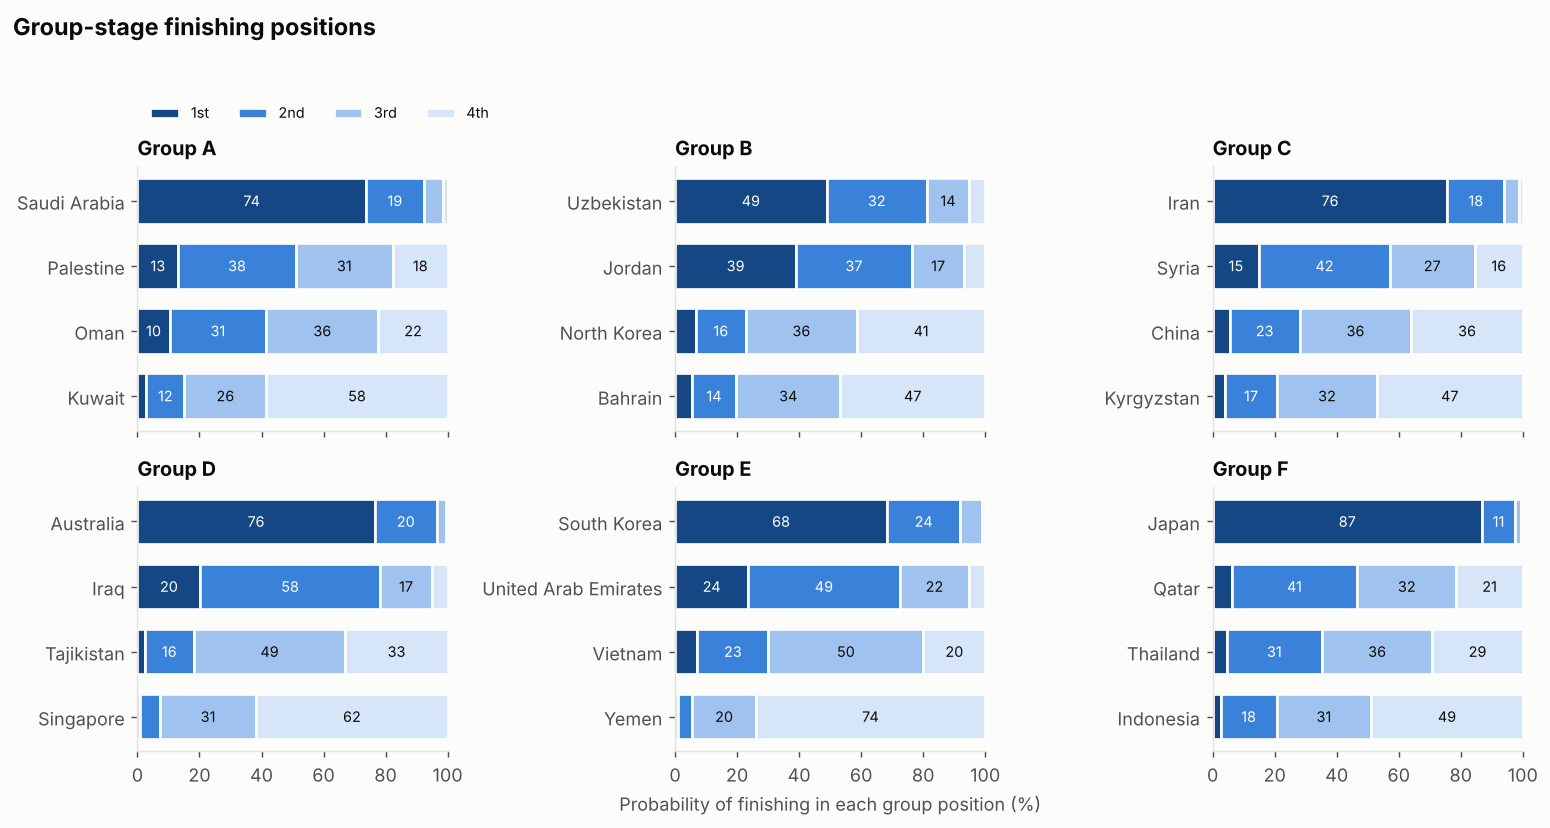

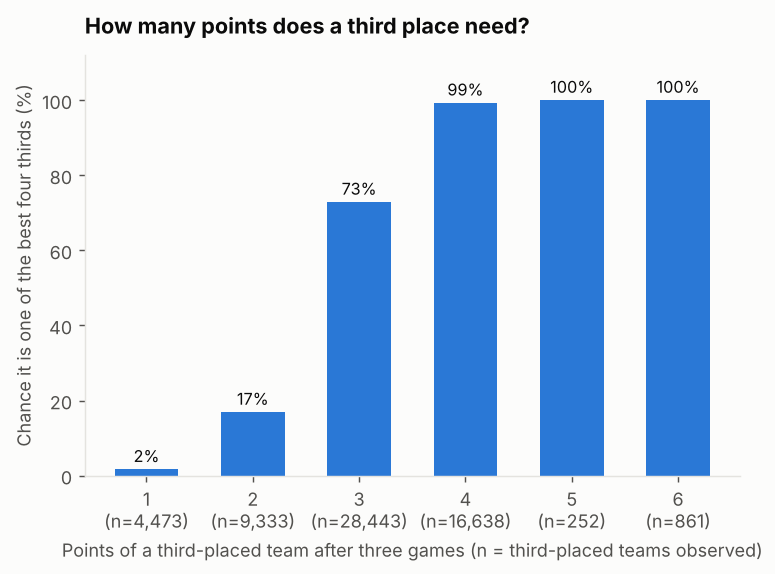

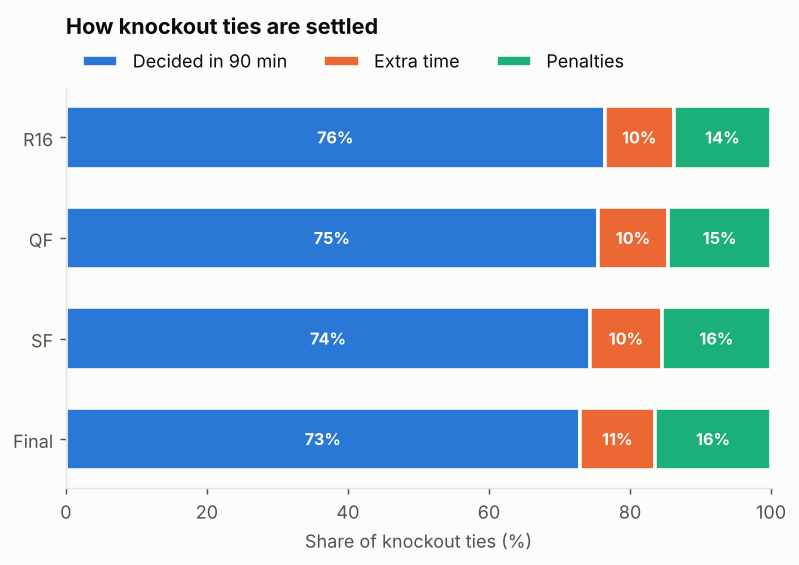

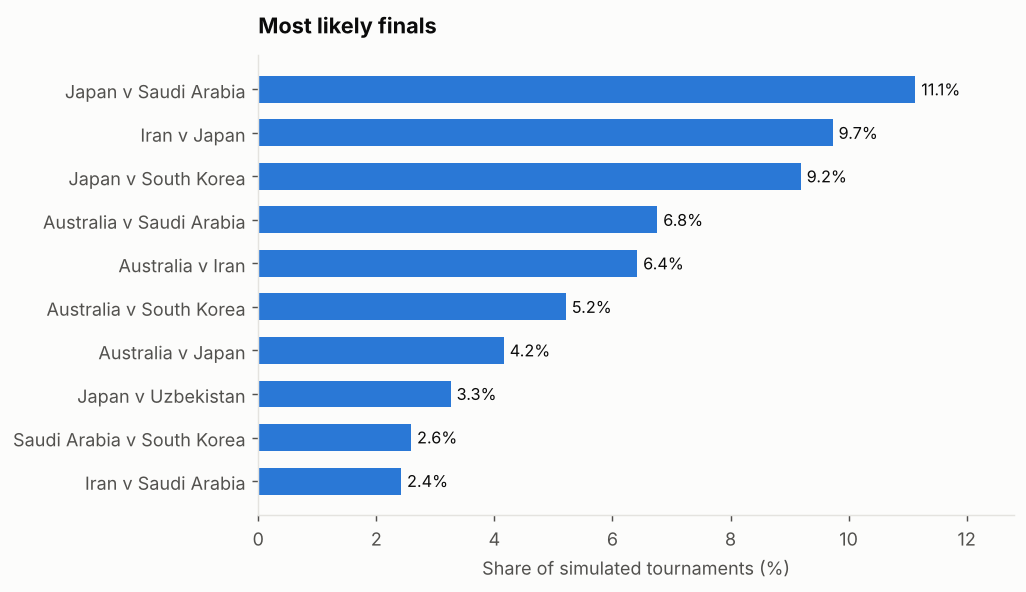

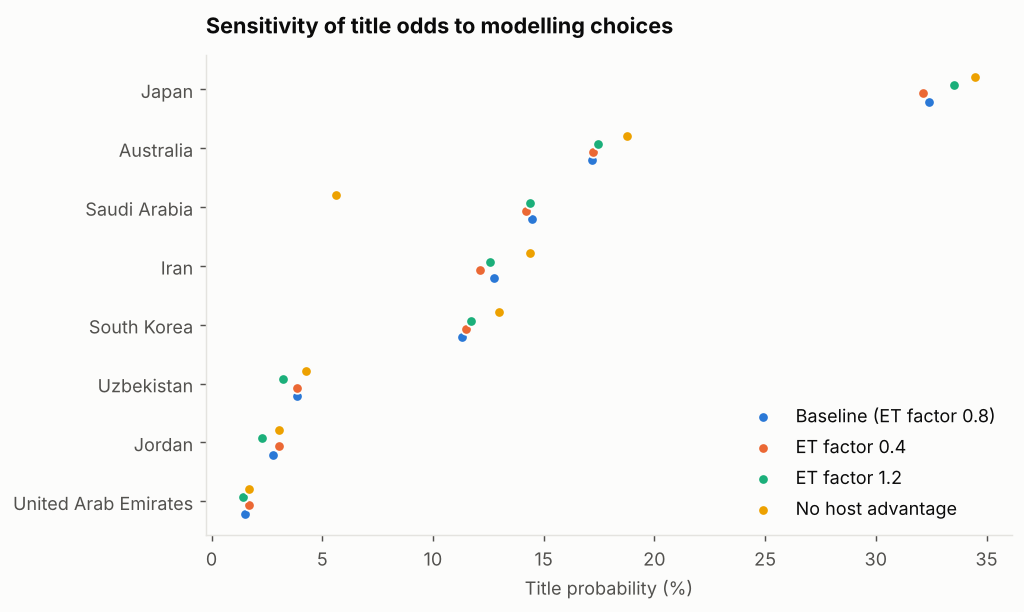

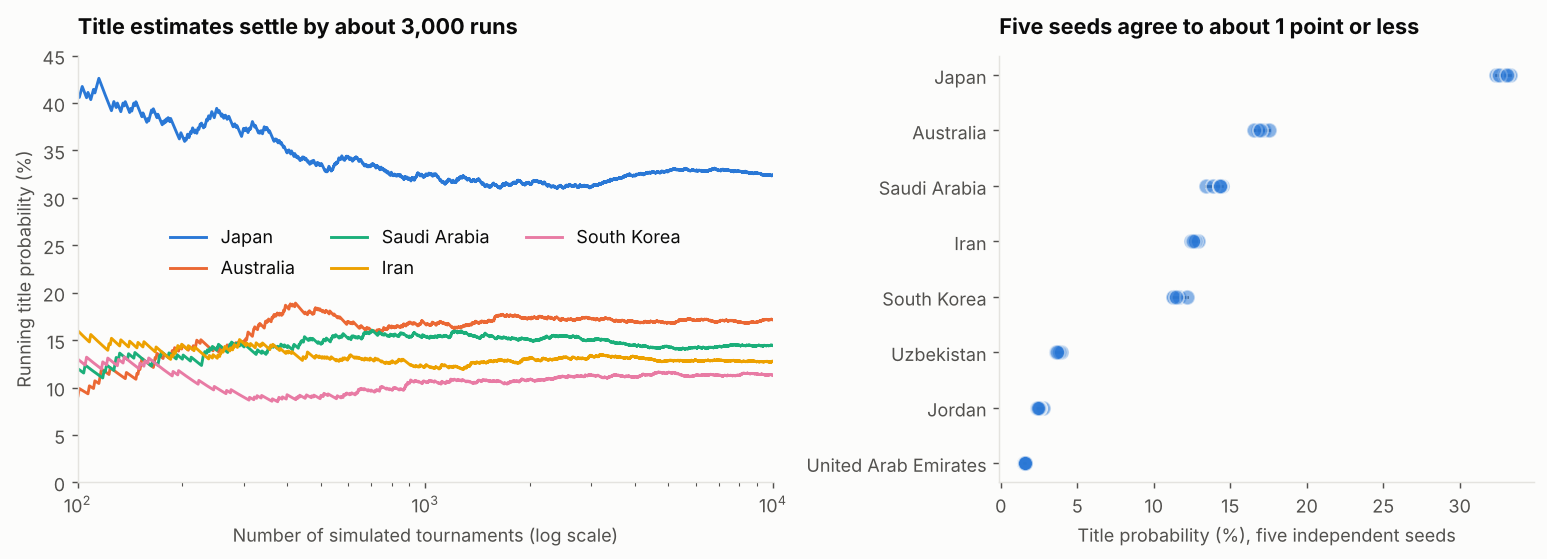

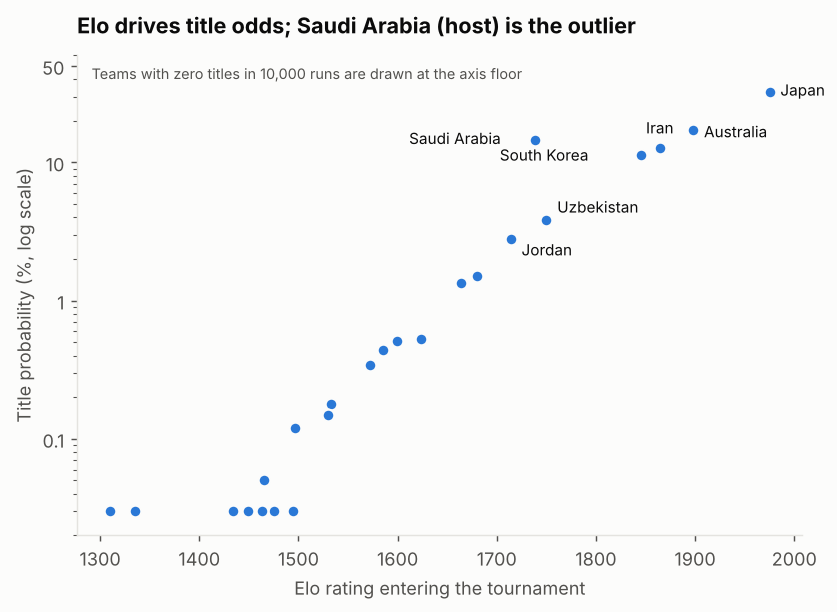

In [5]:
for f in ["01_title_odds","02_stage_heatmap","03_group_positions","04_third_place","05_knockout_resolution",
          "08_likely_finals","09_sensitivity","06_convergence_and_seeds","07_elo_vs_title"]:
    display(Image(f"figures/{f}.png", width=760))